# Задача 4.1
# Шары с возвращением и без возвращения

## Условие
В корзине 23 шара: 8 белых, 6 синих, 9 красных. Извлекают 6 шаров. Найти вероятности: $A$ — все красные; $B$ — 3 синих, 2 белых, 1 красный; $D$ — ровно 4 белых. Рассмотреть извлечение с возвращением, в частности событие $A$.

## Теория с нуля и решение вручную
### 1. Равновозможные исходы и сочетания
Если все элементарные исходы одинаково вероятны, $P(E)=m/M$, где $M$ — число всех исходов, $m$ — число благоприятных. Здесь порядок шаров не важен, поэтому считаем наборы. Число способов выбрать $k$ различных объектов из $n$ без учёта порядка:
$$\binom nk=\frac{n!}{k!(n-k)!},\quad n!=1\cdot2\cdots n,\quad 0!=1.$$
Деление на $k!$ убирает перестановки одного набора. Все $\binom{23}{6}=100947$ наборов равновозможны: каждому соответствует одинаковое число упорядоченных извлечений.

### 2. Извлечение без возвращения
Число оставшихся шаров уменьшается, поэтому извлечения зависимы. Для нескольких цветов используется многомерная гипергеометрическая формула:
$$P(W=w,B=b,R=r)=\frac{\binom8w\binom6b\binom9r}{\binom{23}{6}},\qquad w+b+r=6.$$
Выбираем нужные шары каждого цвета независимо на этапе подсчёта наборов; число вариантов перемножаем.
$$P(A)=\frac{\binom96}{\binom{23}{6}}=\frac4{4807}\approx0.00083212.$$
Вручную можно также перемножить условные вероятности:
$$P(A)=\frac9{23}\frac8{22}\frac7{21}\frac6{20}\frac5{19}\frac4{18}.$$
$$P(B)=\frac{\binom63\binom82\binom91}{\binom{23}{6}}=\frac{240}{4807}\approx0.04992719.$$
Для $D$ остальные два шара могут быть любого небелого цвета. Небелых всего $6+9=15$:
$$P(D)=\frac{\binom84\binom{15}2}{\binom{23}{6}}=\frac{350}{4807}\approx0.07281048.$$

### 3. Извлечение с возвращением
После каждого извлечения состав корзины восстанавливается. Извлечения независимы, вероятности цветов постоянны. Для заданного состава применяется мультиномиальная формула:
$$P(W=w,B=b,R=r)=\frac{6!}{w!b!r!}\left(\frac8{23}\right)^w\left(\frac6{23}\right)^b\left(\frac9{23}\right)^r.$$
Множитель считает порядки расположения цветов. Поэтому
$$P(A)=\left(\frac9{23}\right)^6\approx0.0035899470,$$
$$P(B)=\frac{6!}{2!3!1!}\left(\frac8{23}\right)^2\left(\frac6{23}\right)^3\frac9{23},\qquad P(D)=\binom64\left(\frac8{23}\right)^4\left(\frac{15}{23}\right)^2.$$
Частота $0.00358549$ из условия является приближённой экспериментальной оценкой, а точная вероятность следует из модели. По одной частоте нельзя восстановить точную вероятность без описания опыта.

### 4. Как моделировать тот же опыт
Для каждого из шести шагов выбираем случайный целый номер среди оставшихся шаров. Первые $w$ номеров соответствуют белым, следующие $b$ — синим, остальные — красным. Без возвращения уменьшаем запас выбранного цвета. С возвращением достаточно шесть раз выбрать номер от 0 до 22. Для редкого $A$ используем $N=500000$: ожидается около 416 успехов без возвращения, поэтому заметные колебания естественны.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

Точная дробь: 4/4807
Без возвращения, A: успехов 426, знаменатель 500000
  частота = 0.00085200; ориентир 95%: [0.00077113; 0.00093287]
  теория = 0.00083212; разность = +0.00001988


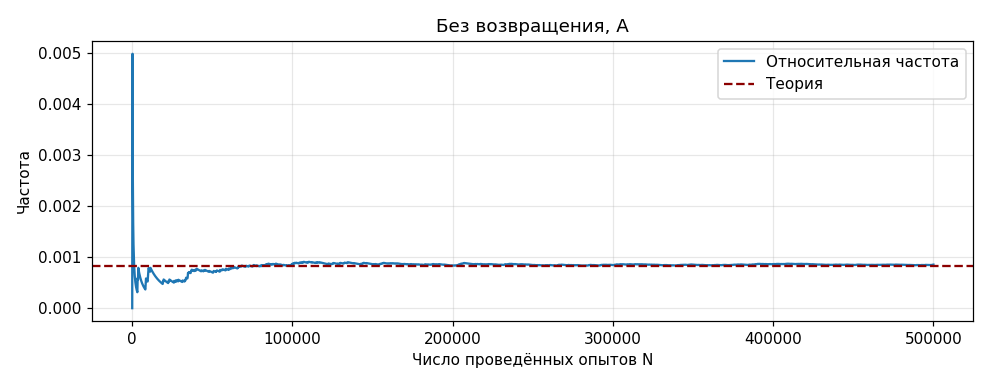

Точная дробь: 240/4807
Без возвращения, B: успехов 24996, знаменатель 500000
  частота = 0.04999200; ориентир 95%: [0.04938793; 0.05059607]
  теория = 0.04992719; разность = +0.00006481


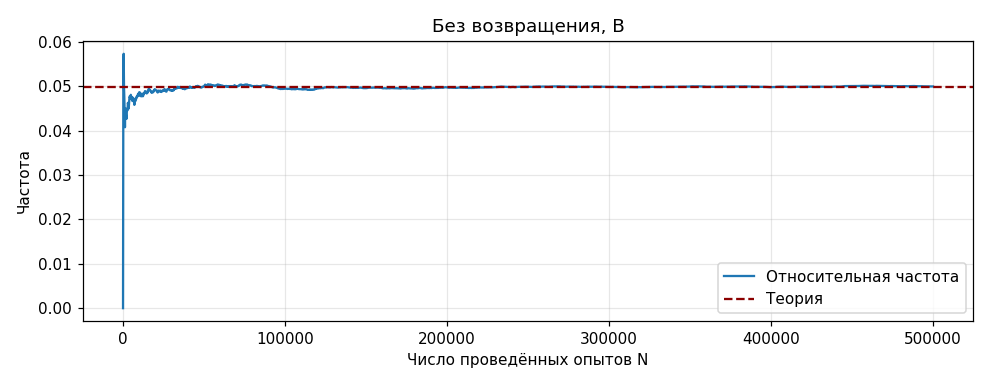

Точная дробь: 350/4807
Без возвращения, D: успехов 36505, знаменатель 500000
  частота = 0.07301000; ориентир 95%: [0.07228889; 0.07373111]
  теория = 0.07281048; разность = +0.00019952


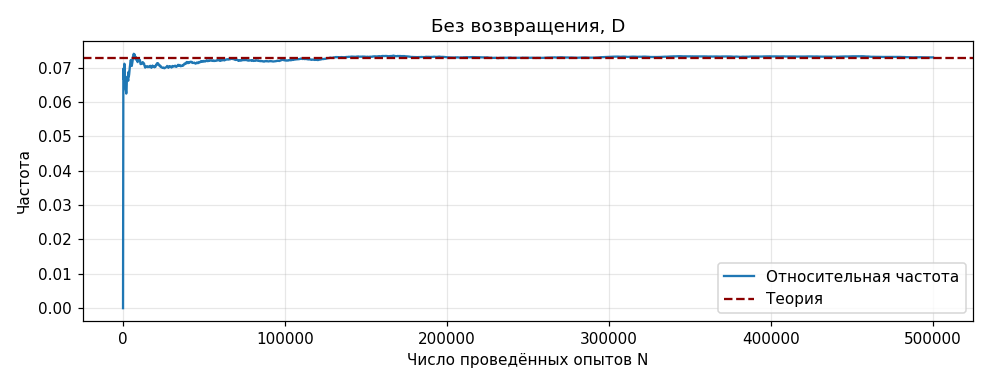

С возвращением, A: успехов 1840, знаменатель 500000
  частота = 0.00368000; ориентир 95%: [0.00351216; 0.00384784]
  теория = 0.00358995; разность = +0.00009005


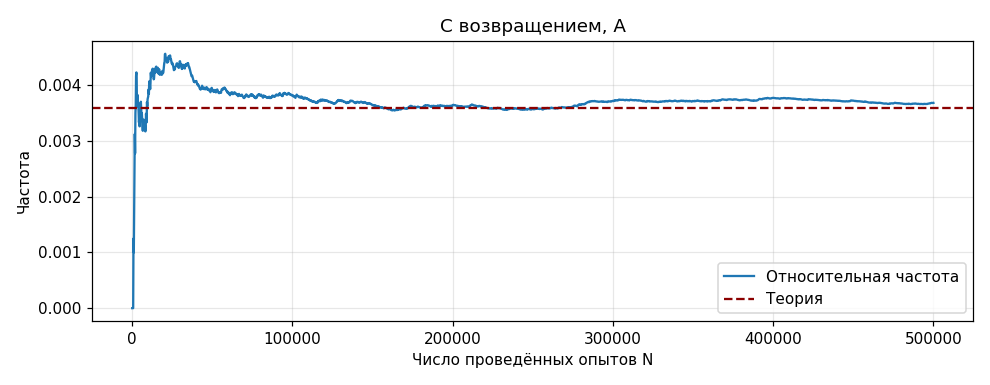

С возвращением, B: успехов 25090, знаменатель 500000
  частота = 0.05018000; ориентир 95%: [0.04957486; 0.05078514]
  теория = 0.05042669; разность = -0.00024669


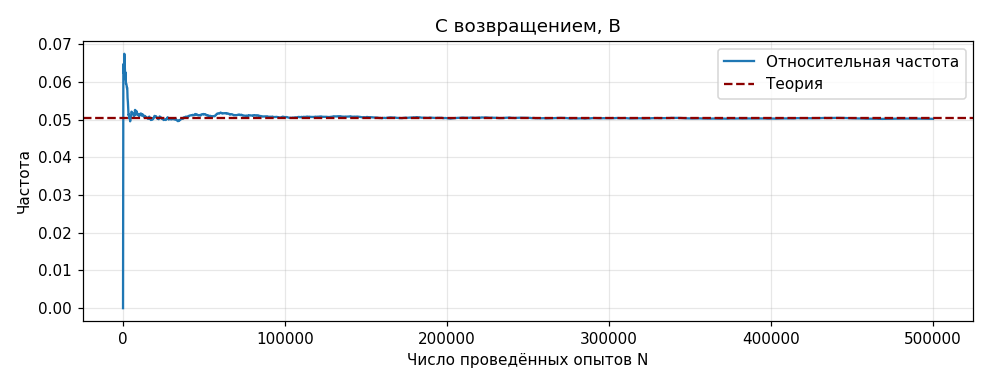

С возвращением, D: успехов 46677, знаменатель 500000
  частота = 0.09335400; ориентир 95%: [0.09254759; 0.09416041]
  теория = 0.09338276; разность = -0.00002876


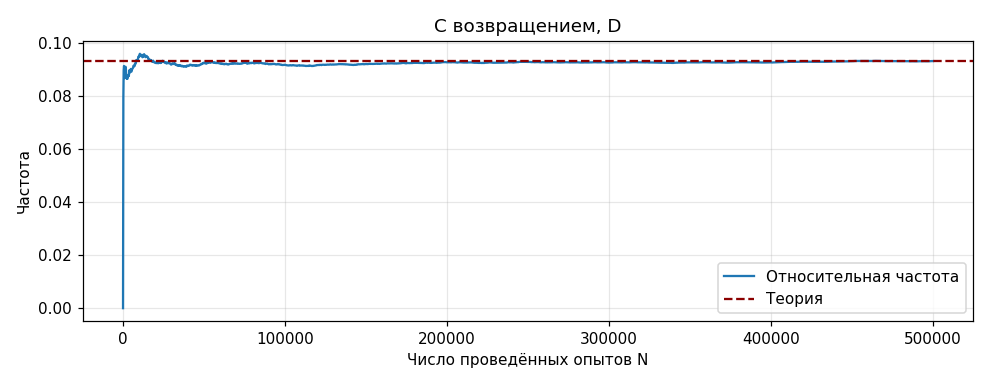

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 500_000
total = math.comb(23, 6)
exact_without = {
    'A': Fraction(math.comb(9, 6), total),
    'B': Fraction(math.comb(6, 3) * math.comb(8, 2) * 9, total),
    'D': Fraction(math.comb(8, 4) * math.comb(15, 2), total),
}
white_left = np.full(N, 8)
blue_left = np.full(N, 6)
white = np.zeros(N, dtype=int)
blue = np.zeros(N, dtype=int)
for step in range(6):
    # Теория 4: на шаге step остаётся 23-step шаров в каждой корзине.
    ball = rng.integers(0, 23-step, size=N)
    is_white = ball < white_left
    is_blue = (ball >= white_left) & (ball < white_left + blue_left)
    white += is_white
    blue += is_blue
    white_left -= is_white
    blue_left -= is_blue
red = 6-white-blue
events = {'A': red == 6, 'B': (blue == 3) & (white == 2) & (red == 1), 'D': white == 4}
for name, event in events.items():
    print('Точная дробь:', exact_without[name])
    report(event, 'Без возвращения, '+name, exact_without[name])

# Теория 3: возвращение сохраняет 23 возможных номера на каждом шаге.
balls = rng.integers(0, 23, size=(N, 6))
white = np.sum(balls < 8, axis=1)
blue = np.sum((balls >= 8) & (balls < 14), axis=1)
red = 6-white-blue
exact_with = {
    'A': Fraction(9, 23)**6,
    'B': 60*Fraction(8, 23)**2*Fraction(6, 23)**3*Fraction(9, 23),
    'D': math.comb(6, 4)*Fraction(8, 23)**4*Fraction(15, 23)**2,
}
events = {'A': red == 6, 'B': (blue == 3) & (white == 2) & (red == 1), 'D': white == 4}
for name, event in events.items():
    report(event, 'С возвращением, '+name, exact_with[name])
